> **Earlier sample investigation.** For the completed full-vintage dataset and modeling inputs, start with [02_modeling_data_handoff.ipynb](02_modeling_data_handoff.ipynb). Sample data below are kept separately and must not be appended to the full-vintage tables.

# From Probability of Default to Expected Credit Loss
## 01 · Data cleaning and inspection

**Question:** Which mortgages are likely to default, how much could a lender lose, and how does that change under economic stress?

This notebook prepares the first evidence base: untouched Freddie Mac annual sample archives, cleaned origination and monthly performance records, and checks of data quality and follow-up. Models, calibration, expected loss, and scenario estimates come later.

**Run all cells in order.** The notebook processes every loan ZIP in `data/raw/` in chunks, writes Parquet, and displays actual results. No loan data means an explicit `awaiting_data` state; there is no synthetic fallback. The combined raw/reference/processed data cap is **10 GB (decimal)**, with processing headroom.

Official sources: [dataset and access](https://www.freddiemac.com/research/datasets/sf-loanlevel-dataset), [General User Guide](https://www.freddiemac.com/fmac-resources/research/pdf/user_guide.pdf), [July 2026 layout](https://www.freddiemac.com/fmac-resources/research/pdf/file_layout_july_2026.xlsx), [headers](https://www.freddiemac.com/fmac-resources/research/docs/file_headers_july_2026.zip), and [release notes](https://www.freddiemac.com/fmac-resources/research/pdf/release_notes.pdf). Local reference copies and checksums are in `data/reference/`. Release 48 reports performance through **June 2026**.

### 1. Sample and unit of observation

An origination row represents one mortgage. A performance row represents one mortgage in one reporting month. The linkage key is `loan_identifier`; the monthly key is `(loan_identifier, reporting_period)`. Monthly rows must not be treated as independent loans.

Use the **Standard Dataset annual samples**, containing 50,000 loans per complete vintage. Suggested cohorts are 2006–2008 (crisis-era histories) and 2018–2019 (later underwriting and pandemic-era histories). The inventory below is authoritative for what was actually downloaded. Equal-size annual samples do not reproduce each year's full market volume, so pooled results describe the selected sample portfolio.

Freddie Mac access requires registration/sign-in. Keep original ZIPs in `data/raw/`; do not unzip or combine them with full-population files or another release of the same vintage.

In [1]:
from pathlib import Path
import sys, os, json, shutil, zipfile
from datetime import datetime, timezone

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src' / 'freddie_cleaning.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from the FinalProject folder or its notebooks subfolder.')
sys.path.insert(0, str(ROOT))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.cache' / 'matplotlib'))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb
from IPython.display import display, Markdown
from src.freddie_cleaning import (ORIG_COLUMNS, PERF_COLUMNS, inventory_archives,
                                  iter_raw_chunks, clean_origination, clean_performance)
from src.inspection_pipeline import run_inspection

MAX_DATA_BYTES = 10_000_000_000
CHUNK_ROWS = 100_000
pd.set_option('display.max_columns', 16)
pd.set_option('display.max_rows', 40)
sns.set_theme(style='whitegrid', context='notebook', palette='deep')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def data_size_bytes():
    return sum(p.stat().st_size for p in (ROOT / 'data').rglob('*') if p.is_file())

print('Project:', ROOT)
print('Executed (UTC):', datetime.now(timezone.utc).isoformat())
print(f'Data footprint: {data_size_bytes()/1e9:.3f} GB / {MAX_DATA_BYTES/1e9:.0f} GB')
print(f'Free disk: {shutil.disk_usage(ROOT).free/1e9:.2f} GB')

Project: /Users/stevenxu/Desktop/MATH789/FinalProject
Executed (UTC): 2026-11-22T21:46:29.693854+00:00
Data footprint: 0.199 GB / 10 GB
Free disk: 16.89 GB


In [2]:
inventory = inventory_archives(ROOT / 'data' / 'raw', max_bytes=MAX_DATA_BYTES)
if inventory.empty:
    display(Markdown('**Awaiting loan files.** Download annual sample ZIPs from Clarity into `data/raw/`, then rerun all cells.'))
else:
    display(inventory[['cohort', 'kind', 'member', 'uncompressed_bytes', 'compressed_bytes']])
    archive_bytes = inventory.drop_duplicates('archive')['archive_bytes'].sum()
    print(f'{inventory.archive.nunique()} archives; {archive_bytes/1e6:.1f} MB compressed; '
          f'{inventory.uncompressed_bytes.sum()/1e9:.3f} GB text inside ZIPs (not extracted).')
    assert data_size_bytes() <= MAX_DATA_BYTES

reference_manifest = pd.read_json(ROOT / 'data' / 'reference' / 'manifest.json')
display(reference_manifest[['file', 'bytes', 'retrieved_date']])

,cohort,kind,member,uncompressed_bytes,compressed_bytes
0,2006,origination,sample_orig_2006.txt,6411591,1159104
1,2006,performance,sample_perf_2006.txt,371120974,46754972
2,2007,origination,sample_orig_2007.txt,6390439,1162868
3,2007,performance,sample_perf_2007.txt,348461816,44662474
4,2008,origination,sample_orig_2008.txt,6367690,1163011
5,2008,performance,sample_perf_2008.txt,281381854,35760160
6,2018,origination,sample_orig_2018.txt,6346800,1198436
7,2018,performance,sample_perf_2018.txt,237773109,33228555
8,2019,origination,sample_orig_2019.txt,6378356,1214305
9,2019,performance,sample_perf_2019.txt,226717332,31887275


5 archives; 198.2 MB compressed; 1.497 GB text inside ZIPs (not extracted).


,file,bytes,retrieved_date
0,user_guide.pdf,409857,2026-11-22
1,file_layout_july_2026.xlsx,13753,2026-11-22
2,file_headers_july_2026.zip,1217,2026-11-22
3,release_notes.pdf,664895,2026-11-22


### 2. Verify the current schema

The July 2026 release changed field locations. Older column lists can silently shift values into the wrong variables. The parser checks **every row** against the current 31-field origination / 35-field performance layout and stops on a mismatch. Identifier, state, ZIP-prefix, and categorical codes are read as strings before any conversion.

In [3]:
with zipfile.ZipFile(ROOT / 'data' / 'reference' / 'file_headers_july_2026.zip') as z:
    orig_headers = z.read('origination_data_file_header.txt').decode('utf-8-sig').strip().split('|')
    perf_headers = z.read('performance_data_file_header.txt').decode('utf-8-sig').strip().split('|')
assert len(orig_headers) == len(ORIG_COLUMNS) == 31
assert len(perf_headers) == len(PERF_COLUMNS) == 35
schema = pd.concat([
    pd.DataFrame({'table': 'origination', 'position': range(1, 32),
                  'official_name': orig_headers, 'python_name': ORIG_COLUMNS}),
    pd.DataFrame({'table': 'performance', 'position': range(1, 36),
                  'official_name': perf_headers, 'python_name': PERF_COLUMNS})
], ignore_index=True)
with pd.option_context('display.max_rows', 70):
    display(schema)

,table,position,official_name,python_name
0,origination,1,CLASSIC FICO,classic_fico
1,origination,2,FIRST PAYMENT DATE,first_payment_date
2,origination,3,FIRST TIME HOMEBUYER INDICATOR,first_time_homebuyer_indicator
3,origination,4,MATURITY DATE,maturity_date
4,origination,5,METROPOLITAN STATISTICAL AREA (MSA) OR METROPO...,metropolitan_statistical_area
5,origination,6,MORTGAGE INSURANCE PERCENTAGE (MI %),mortgage_insurance_percentage
6,origination,7,NUMBER OF UNITS,number_of_units
7,origination,8,OCCUPANCY STATUS,occupancy_status
8,origination,9,ORIGINAL COMBINED LOAN-TO-VALUE (CLTV),original_cltv
9,origination,10,ORIGINAL DEBT-TO-INCOME (DTI) RATIO,original_dti


### 3. Cleaning rules and a raw-to-clean preview

Cleaning is deterministic and does not learn from future data. Raw archives remain untouched; field audits record conversions and anomalies. We retain all source rows, including duplicates, with archive/member/row provenance.

| Field group | Treatment |
|---|---|
| FICO / VantageScore | Map documented unavailable codes to missing; check range |
| Ratios and counts | Apply each field's sentinel and vintage-specific range |
| Dates | Parse exact `YYYYMM` into calendar-month timestamps; audit malformed values |
| Delinquency | Keep raw code; `XX` unavailable, `RA` REO, numeric `99` valid severe status |
| Recovery / costs | Preserve absence, zero, and negative amounts as distinct where permitted |
| Duplicates / linkage | Count identical rows, conflicting keys, and unmatched identifiers separately |

The inspection flag `serious_delinquency` means an observed numeric status of at least three months delinquent or REO (`RA`). It is not yet the project's future default target. No imputation, scaling, winsorization, or silent duplicate removal occurs here. See `src/freddie_cleaning.py` for the full rules.

In [4]:
if not inventory.empty and inventory.kind.eq('origination').any():
    first_orig = inventory.loc[inventory.kind.eq('origination')].iloc[0]
    reader = iter_raw_chunks(first_orig.archive, first_orig.member, 'origination', chunksize=1000)
    raw_preview = next(reader)
    reader.close()
    clean_preview, preview_audit = clean_origination(raw_preview)
    preview_fields = ['loan_identifier', 'classic_fico', 'first_payment_date',
                      'original_ltv', 'original_dti', 'mortgage_insurance_percentage']
    display(pd.concat({'raw': raw_preview[preview_fields].head(),
                       'clean': clean_preview[preview_fields].head()}, axis=1))
    display(preview_audit)
else:
    print('Raw-to-clean preview requires a real origination file.')

raw                                                            \
  loan_identifier classic_fico first_payment_date original_ltv original_dti   
0    F06Q10000059          776             200603           82           45   
1    F06Q10000079          639             200603           81           42   
2    F06Q10000090          707             200603           82           46   
3    F06Q10000095          722             200603           72           57   
4    F06Q10000110          772             200604           62           24   

                                          clean               \
  mortgage_insurance_percentage loan_identifier classic_fico   
0                            12    F06Q10000059          776   
1                            12    F06Q10000079          639   
2                            12    F06Q10000090          707   
3                             0    F06Q10000095          722   
4                             0    F06Q10000110          772   

                                                                              
  first_payment_date original_ltv original_dti mortgage_insurance_percentage  
0         2006-03-01           82           45                            12  
1         2006-03-01           81           42                            12  
2         2006-03-01           82           46                            12  
3         2006-03-01           72           57                             0  
4         2006-04-01           62           24                             0

,field,raw_rows,raw_blank_count,sentinel_count,sentinel_values,malformed_count,range_violation_count,code_violation_count,whitespace_trimmed_count,cleaned_missing_count
0,classic_fico,1000,0,0,9999,0,0,0,0,0
1,first_payment_date,1000,0,0,,0,0,0,0,0
2,first_time_homebuyer_indicator,1000,0,0,9,0,0,0,0,0
3,maturity_date,1000,0,0,,0,0,0,0,0
4,metropolitan_statistical_area,1000,202,0,,0,0,0,0,202
5,mortgage_insurance_percentage,1000,0,0,999,0,0,0,0,0
6,number_of_units,1000,0,0,99,0,0,0,0,0
7,occupancy_status,1000,0,0,9,0,0,0,0,0
8,original_cltv,1000,0,0,999,0,0,0,0,0
9,original_dti,1000,0,24,999,0,0,0,0,24


### 4. Process all selected records

This cell streams ZIP members into compressed Parquet shards, then uses DuckDB for cross-file checks. It may take several minutes. It checks the combined data footprint during processing, reserves scratch space, and retains the prior successful output if a new run fails. Outputs are under `data/processed/freddie_inspection/`.

In [5]:
result = run_inspection(ROOT, chunksize=CHUNK_ROWS, max_bytes=MAX_DATA_BYTES)
HAS_DATA = result['status'] == 'complete'
print('Inspection status:', result['status'])
print('Structural checks passed:', result['structural_quality_pass'])
print('Modeling ready:', result['modeling_ready'], '(no prediction labels have been constructed)')
display(result['overview'])
for warning in result['warnings']:
    print('•', warning)
if HAS_DATA:
    print(f'Current data footprint: {result["data_footprint_bytes"]/1e9:.3f} GB')
    display(result['inventory'][['member', 'archive_bytes', 'archive_sha256']])

def show_table(name, rows=25):
    table = result[name]
    if table.empty:
        print(f'{name}: no observations available.')
    else:
        display(table.head(rows))

Starting member 1/10: sample_2006.zip:sample_orig_2006.txt (origination)


Finished sample_2006.zip:sample_orig_2006.txt: 50,000 rows in 1 chunks


Starting member 2/10: sample_2006.zip:sample_perf_2006.txt (performance)


  sample_2006.zip:sample_perf_2006.txt: 500,000 rows written in 5 chunks


  sample_2006.zip:sample_perf_2006.txt: 1,000,000 rows written in 10 chunks


  sample_2006.zip:sample_perf_2006.txt: 1,500,000 rows written in 15 chunks


... (41 outputs left out)

Inspection status: complete
Structural checks passed: True
Modeling ready: False (no prediction labels have been constructed)


,kind,rows,columns,distinct_loans
0,origination,250000,36,250000
1,performance,12748791,42,250000


• No prediction labels or fixed outcome horizon have been constructed; modeling_ready is false.
• Observed serious delinquency means numeric status >=3 months or RA anywhere in the supplied records; entirely unknown statuses stay unknown. It is not a 12-month default label.
• Category distributions show up to 100 values per field; fractions use all origination records.
Current data footprint: 0.911 GB


,member,archive_bytes,archive_sha256
0,sample_orig_2006.txt,47914434,5a704b2ba4b8bfe4571331dccf6ed6cdd4b1e4181ede43...
1,sample_perf_2006.txt,47914434,5a704b2ba4b8bfe4571331dccf6ed6cdd4b1e4181ede43...
2,sample_orig_2007.txt,45825700,7704cd03e7ddc2a373fd34fea0f0286d80863db19c7d4d...
3,sample_perf_2007.txt,45825700,7704cd03e7ddc2a373fd34fea0f0286d80863db19c7d4d...
4,sample_orig_2008.txt,36923529,e279a97b0f899b5736a1a657b8137afb0aa1c22fc3208a...
5,sample_perf_2008.txt,36923529,e279a97b0f899b5736a1a657b8137afb0aa1c22fc3208a...
6,sample_orig_2018.txt,34427349,436616d0e628b85572fbaba144b2ce2c26e92cee694011...
7,sample_perf_2018.txt,34427349,436616d0e628b85572fbaba144b2ce2c26e92cee694011...
8,sample_orig_2019.txt,33101938,e943fe71352c414a3efd8b039a78689af0ffd422ab7a8e...
9,sample_perf_2019.txt,33101938,e943fe71352c414a3efd8b039a78689af0ffd422ab7a8e...


### 5. Missingness and anomalies

Missingness can reflect historical disclosure availability or a non-applicable field. It is not necessarily an error. For example, appraisal-method and estimated-LTV coverage differ across historical periods. Review missingness by cohort before choosing features.

Malformed or out-of-range values become missing in cleaned fields and remain traceable to raw data. The audit separates these failures from documented unavailable codes. Correctly unavailable values do not by themselves fail the structural check.

,kind,issue,count
0,origination,cleaned_missing,1026167
1,origination,raw_blank,529068
2,origination,sentinel,497099
3,performance,cleaned_missing,297098113
4,performance,raw_blank,277105257
5,performance,sentinel,19992856


,kind,column,issue,count


,kind,column,missing_count,row_count,missing_fraction
30,origination,vantagescore_4,250000,250000,1.000000
25,origination,pre_harp_loan_sequence_number,249459,250000,0.997836
28,origination,property_valuation_method,243051,250000,0.972204
26,origination,special_eligibility_program,239648,250000,0.958592
4,origination,metropolitan_statistical_area,39961,250000,0.159844
9,origination,original_dti,3763,250000,0.015052
0,origination,classic_fico,152,250000,0.000608
22,origination,number_of_borrowers,65,250000,0.000260
34,origination,borrowers_top_coded_2plus,65,250000,0.000260
2,origination,first_time_homebuyer_indicator,41,250000,0.000164


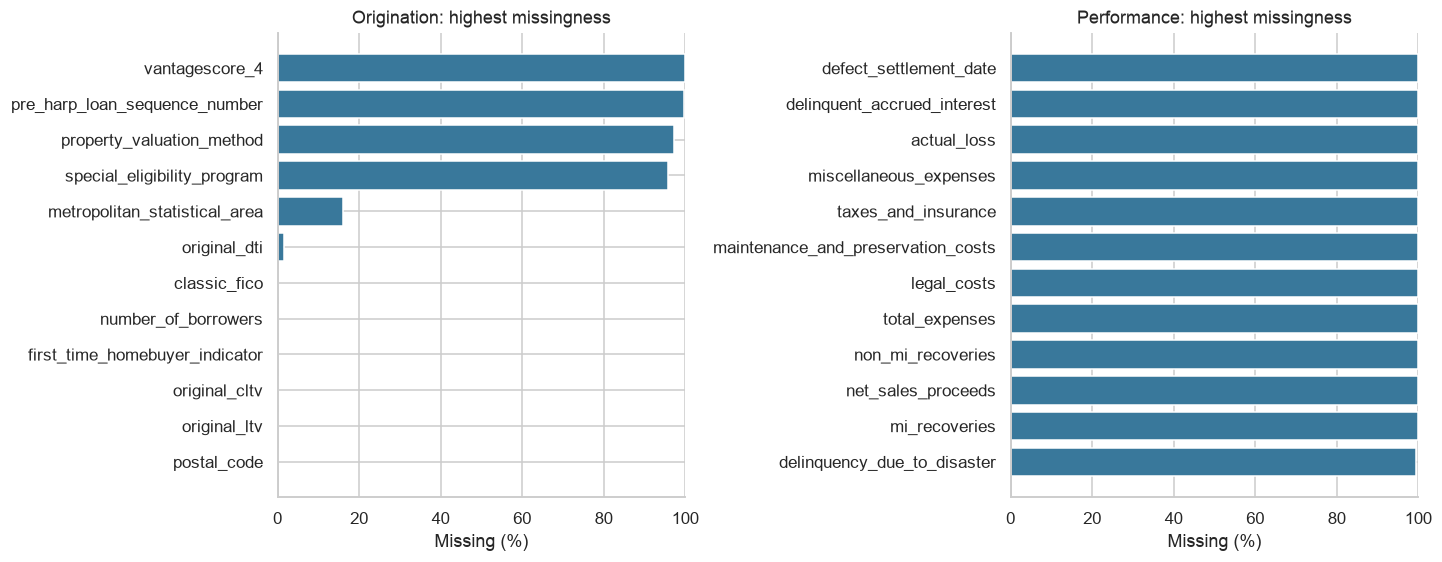

In [6]:
audit = result['cleaning_audit']
if not audit.empty:
    display(audit.groupby(['kind', 'issue'], as_index=False)['count'].sum())
    problems = audit.loc[audit.issue.isin(['malformed', 'range_violation', 'code_violation', 'empty_member'])]
    display(problems.sort_values('count', ascending=False).head(30))
missing = result['missingness']
if not missing.empty:
    display(missing.sort_values(['kind', 'missing_fraction'], ascending=[True, False]).head(30))
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
    for ax, kind in zip(axes, ['origination', 'performance']):
        m = missing.loc[missing.kind.eq(kind) & missing.column.isin(ORIG_COLUMNS + PERF_COLUMNS)]
        m = m.nlargest(12, 'missing_fraction').sort_values('missing_fraction')
        ax.barh(m.column, 100*m.missing_fraction, color='#39789b')
        ax.set(title=f'{kind.title()}: highest missingness', xlabel='Missing (%)', xlim=(0, 100))
    plt.show()

### 6. Loan characteristics

These distributions describe the downloaded sample. They are not fitted model inputs yet. Monetary balances are in US dollars; LTV and DTI are percentages, not fractions. Original UPB is rounded in the source. A zero mortgage-insurance percentage is valid and means no insurance.

,column,count,mean,std,min,25%,50%,75%,max
0,classic_fico,249848.0,737.268771,52.776715,300.0,701.0,746.0,781.0,850.0
1,mortgage_insurance_percentage,250000.0,5.70532,10.894636,0.0,0.0,0.0,0.0,40.0
2,number_of_units,250000.0,1.0318,0.229811,1.0,1.0,1.0,1.0,4.0
3,original_cltv,249986.0,73.901795,18.085581,5.0,65.0,80.0,88.0,255.0
4,original_dti,246237.0,36.081787,11.308761,1.0,28.0,37.0,44.0,65.0
5,original_upb,250000.0,210381.948,115246.950117,9000.0,122000.0,186000.0,280000.0,1397000.0
6,original_ltv,249988.0,72.548618,17.64308,5.0,64.0,78.0,80.0,222.0
7,original_interest_rate,250000.0,5.558763,1.024281,2.35,4.75,5.875,6.375,9.79
8,original_loan_term,250000.0,334.673596,61.152534,60.0,360.0,360.0,360.0,480.0
9,number_of_borrowers,249935.0,1.50858,0.509166,1.0,1.0,2.0,2.0,5.0


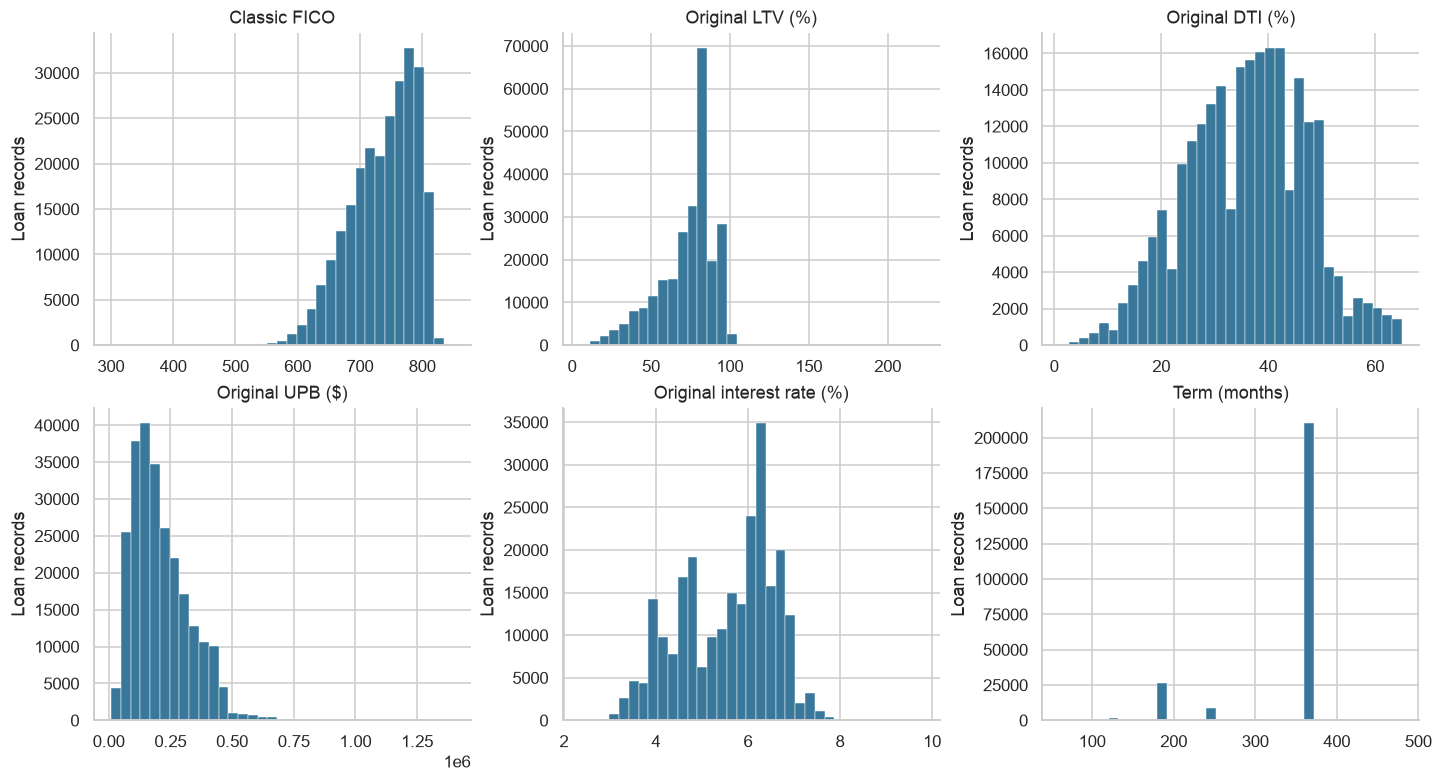

,classic_fico,original_ltv,original_dti,original_upb,original_interest_rate,original_loan_term
source_cohort,,,,,,
2006,729.0,77.0,37.0,158000.0,6.38,360.0
2007,732.0,77.0,37.0,160000.0,6.38,360.0
2008,753.0,75.0,36.0,183000.0,6.00,360.0
2018,753.0,80.0,37.0,207000.0,4.75,360.0
2019,757.0,80.0,37.0,232000.0,4.12,360.0


,column,value,count,fraction
103,occupancy_status,P,220474,0.881896
104,occupancy_status,I,17470,0.069880
105,occupancy_status,S,12056,0.048224
113,property_state,CA,23986,0.095944
114,property_state,TX,17825,0.071300
115,property_state,FL,15946,0.063784
116,property_state,IL,12421,0.049684
117,property_state,NC,8785,0.035140
118,property_state,MI,8722,0.034888
119,property_state,OH,8705,0.034820


In [7]:
orig = result['origination']
show_table('origination_describe', 30)
if not orig.empty:
    fields = {'classic_fico': 'Classic FICO', 'original_ltv': 'Original LTV (%)',
              'original_dti': 'Original DTI (%)', 'original_upb': 'Original UPB ($)',
              'original_interest_rate': 'Original interest rate (%)', 'original_loan_term': 'Term (months)'}
    fig, axes = plt.subplots(2, 3, figsize=(13, 7), constrained_layout=True)
    for ax, (column, title) in zip(axes.flat, fields.items()):
        values = pd.to_numeric(orig[column], errors='coerce').dropna()
        ax.hist(values, bins=35, color='#39789b', edgecolor='white', linewidth=.3)
        ax.set(title=title, ylabel='Loan records')
    plt.show()
    display(orig.groupby('source_cohort')[list(fields)].median().round(2))
    selected = result['category_distributions'].query("column in ['loan_purpose', 'occupancy_status', 'property_type', 'property_state']")
    display(selected.groupby('column', group_keys=False).head(8))

### 7. Duplicate keys and linkage

An exact duplicate repeats the original parsed fields. A conflicting key has distinct original records for the same loan (origination) or loan-month (performance). No arbitrary 'keep last' rule is applied because file order does not establish authority. Resolve these issues before making a one-to-many join for modeling.

In [8]:
show_table('duplicate_quality')
show_table('linkage_quality')
if HAS_DATA:
    d = result['duplicate_quality']
    n = int(d['conflicting_keys'].sum())
    display(Markdown(f'**Conflicting keys requiring investigation: {n:,}.** '
                     'Zero conflicts does not establish complete follow-up or validate a future outcome definition.'))

,kind,total_rows,exact_duplicate_excess_rows,key_duplicate_excess_rows,conflicting_keys,invalid_key_rows
0,origination,250000,0,0,0,0
1,performance,12748791,0,0,0,0


,metric,count
0,performance_rows_without_origination,0
1,performance_loans_without_origination,0
2,origination_loans_without_performance,0
3,linked_loans,250000


**Conflicting keys requiring investigation: 0.** Zero conflicts does not establish complete follow-up or validate a future outcome definition.

### 8. Performance coverage and observed outcomes

Performance starts at Freddie Mac acquisition, not necessarily origination. A loan with twelve records may still have calendar gaps. The coverage table measures distinct months and internal gaps between first and last observations; it does not detect all missing history before acquisition or after exit.

The observed-serious-delinquency count uses all supplied follow-up and is affected by different observation lengths. Do not compare it as a fixed-horizon default rate or use it directly as the training label. Loan age may reset after modification, so future windows must use calendar months.

,cohort,loans,performance_rows,linked_loans,median_observed_months,observed_serious_delinquency_loans
0,2006,50000,3206738,50000,51.0,7166
1,2007,50000,3015985,50000,47.0,8244
2,2008,50000,2459814,50000,36.0,4659
3,2018,50000,2089132,50000,30.0,2721
4,2019,50000,1977122,50000,24.5,2799


,distinct_months,span_months,gap_months
count,250000.00,250000.00,250000.00
mean,51.00,51.00,0.00
std,43.07,43.08,0.17
min,1.00,1.00,0.00
25%,20.00,20.00,0.00
50%,37.00,37.00,0.00
75%,74.00,74.00,0.00
max,246.00,246.00,56.00


Loans with internal calendar gaps: 76
Loans with entirely unknown observed delinquency: 0


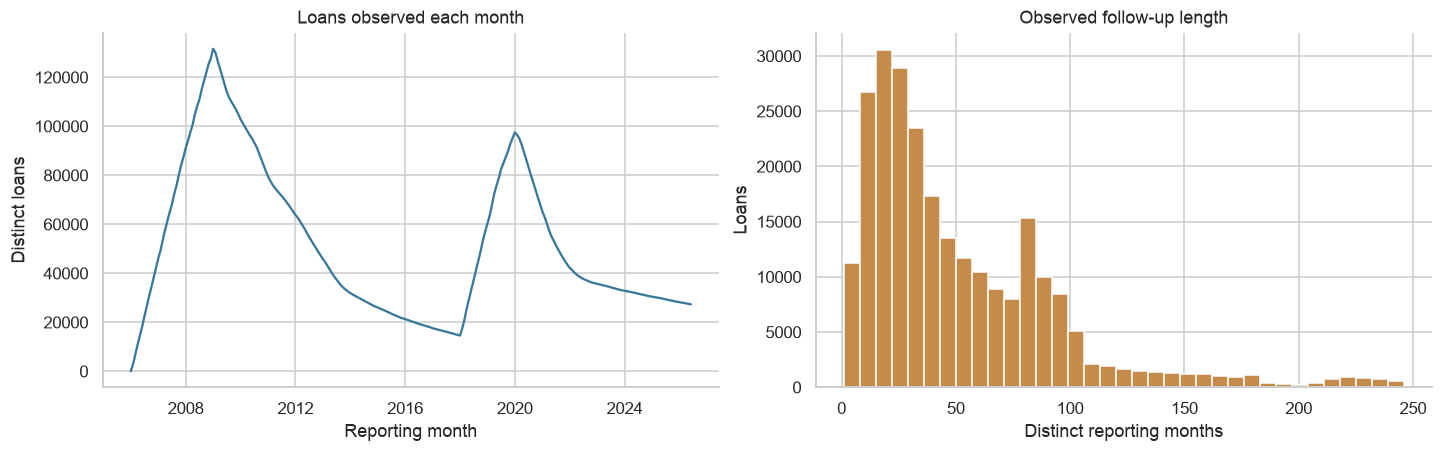

In [9]:
show_table('cohort_summary')
coverage = result['loan_coverage']
if not coverage.empty:
    display(coverage[['distinct_months', 'span_months', 'gap_months']].describe().round(2))
    print(f'Loans with internal calendar gaps: {coverage.gap_months.gt(0).sum():,}')
    print(f'Loans with entirely unknown observed delinquency: {coverage.observed_serious_delinquency.isna().sum():,}')
    monthly = result['month_counts']
    fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
    axes[0].plot(monthly.reporting_period, monthly.distinct_loans, color='#39789b')
    axes[0].set(title='Loans observed each month', xlabel='Reporting month', ylabel='Distinct loans')
    axes[1].hist(coverage.distinct_months.dropna(), bins=35, color='#c48b4b', edgecolor='white')
    axes[1].set(title='Observed follow-up length', xlabel='Distinct reporting months', ylabel='Loans')
    plt.show()

### 9. Inspect one actual loan's history

The example is selected deterministically from observed serious-delinquency loans, if any exist, otherwise from all observed loans. It illustrates field behavior and is not representative of the portfolio. A zero-balance code can describe voluntary payoff or other exits; zero UPB alone does not define default.

Example loan: F06Q10000685


,loan_identifier,reporting_period,current_actual_upb,delinquency_status,delinquency_months,serious_delinquency,zero_balance_code,modification_flag,actual_loss,source_row
0,F06Q10000685,2006-03-01,221000.00,00,0,False,NaN,NaN,NaN,957
1,F06Q10000685,2006-04-01,221000.00,00,0,False,NaN,NaN,NaN,958
2,F06Q10000685,2006-05-01,221000.00,00,0,False,NaN,NaN,NaN,959
3,F06Q10000685,2006-06-01,220000.00,00,0,False,NaN,NaN,NaN,960
4,F06Q10000685,2006-07-01,220000.00,00,0,False,NaN,NaN,NaN,961
5,F06Q10000685,2006-08-01,220000.00,00,0,False,NaN,NaN,NaN,962
6,F06Q10000685,2006-09-01,220000.00,00,0,False,NaN,NaN,NaN,963
7,F06Q10000685,2006-10-01,219508.97,00,0,False,NaN,NaN,NaN,964
8,F06Q10000685,2006-11-01,219291.51,00,0,False,NaN,NaN,NaN,965
9,F06Q10000685,2006-12-01,219072.91,00,0,False,NaN,NaN,NaN,966


,loan_identifier,reporting_period,current_actual_upb,delinquency_status,delinquency_months,serious_delinquency,zero_balance_code,modification_flag,actual_loss,source_row
157,F06Q10000685,2019-04-01,193474.52,00,0,False,NaN,P,NaN,1114
158,F06Q10000685,2019-05-01,193062.37,00,0,False,NaN,P,NaN,1115
159,F06Q10000685,2019-06-01,193062.37,01,1,False,NaN,P,NaN,1116
160,F06Q10000685,2019-07-01,192562.22,00,0,False,NaN,P,NaN,1117
161,F06Q10000685,2019-08-01,192353.44,00,0,False,NaN,P,NaN,1118
162,F06Q10000685,2019-09-01,192143.97,00,0,False,NaN,P,NaN,1119
163,F06Q10000685,2019-10-01,191933.80,00,0,False,NaN,P,NaN,1120
164,F06Q10000685,2019-11-01,0.00,00,0,False,16,P,NaN,1121


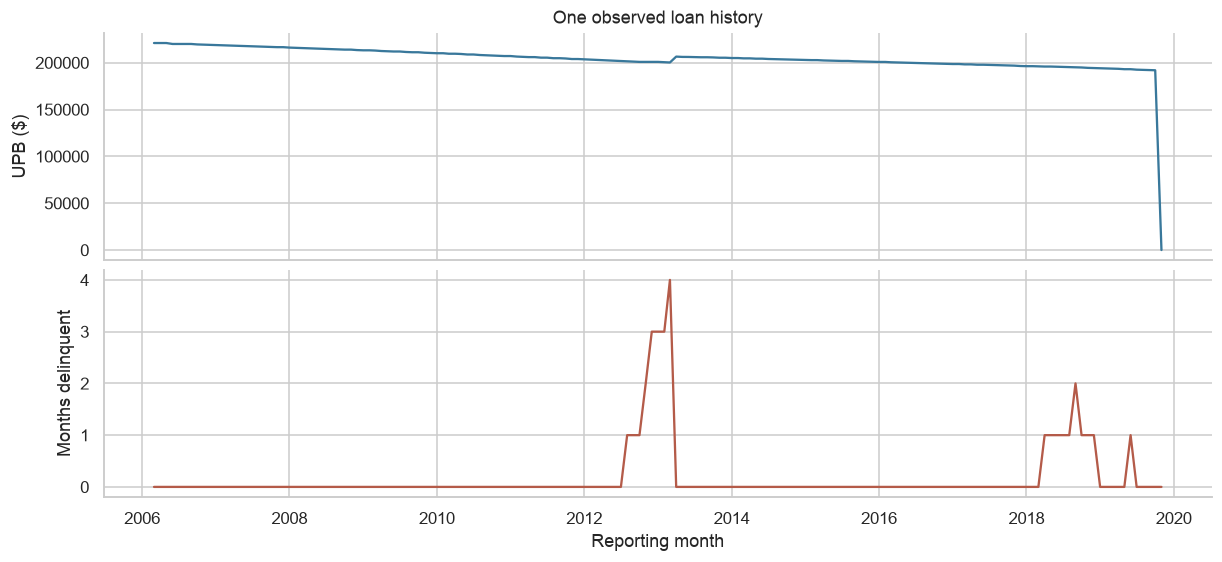

In [10]:
if HAS_DATA and not coverage.empty:
    pool = coverage.loc[coverage.observed_serious_delinquency.fillna(False)]
    example_id = (pool if not pool.empty else coverage).sort_values('loan_identifier').iloc[0].loan_identifier
    with duckdb.connect() as con:
        history = con.execute('''SELECT loan_identifier, reporting_period, current_actual_upb,
                    delinquency_status, delinquency_months, serious_delinquency,
                    zero_balance_code, modification_flag, actual_loss, source_row
                    FROM read_parquet(?, union_by_name=true)
                    WHERE loan_identifier=? ORDER BY reporting_period, source_row''',
                    [result['paths']['performance_glob'], example_id]).df()
    print('Example loan:', example_id)
    display(history.head(12))
    display(history.tail(8))
    fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True, constrained_layout=True)
    axes[0].plot(history.reporting_period, history.current_actual_upb, color='#39789b')
    axes[0].set(ylabel='UPB ($)', title='One observed loan history')
    axes[1].plot(history.reporting_period, history.delinquency_months, color='#b45b49')
    axes[1].set(ylabel='Months delinquent', xlabel='Reporting month')
    plt.show()

### 10. What is available for expected loss?

For a defined horizon and exposure, the project will eventually estimate
\[
\operatorname{ECL}=\sum_i \operatorname{PD}_i\times\operatorname{LGD}_i\times\operatorname{EAD}_i.
\]

This notebook only checks the ingredients. Recovery, expense, and loss fields are usually event-dependent and can be missing before disposition. Do not fill them with zero or treat them as application-time predictors. LGD requires an explicit event definition, recovery window, discounting/cost convention, and handling of unresolved cases. EAD should reflect the relevant future exposure; original principal is not automatically EAD.

**Monthly balance sums below are loan-month totals, not simultaneous portfolio exposure.** A portfolio exposure requires one common reporting date and one row per active loan.

In [11]:
show_table('loss_field_availability', 30)
show_table('balance_summary', 20)
if HAS_DATA:
    with duckdb.connect() as con:
        snapshot = con.execute('''WITH p AS (SELECT * FROM read_parquet(?, union_by_name=true)),
                   latest AS (SELECT max(reporting_period) AS t FROM p)
                   SELECT reporting_period, count(*) AS records, count(DISTINCT loan_identifier) AS loans,
                          sum(current_actual_upb) AS total_reported_upb,
                          count(*)-count(current_actual_upb) AS missing_upb
                   FROM p,latest WHERE reporting_period=t GROUP BY reporting_period''',
                   [result['paths']['performance_glob']]).df()
    display(snapshot)
    print('Latest-month descriptive snapshot; verify duplicates and exits before treating this as EAD.')

,column,nonmissing_count,missing_count,nonzero_count
0,mi_recoveries,9876,12738915,2508
1,net_sales_proceeds,9876,12738915,9782
2,non_mi_recoveries,9876,12738915,8411
3,total_expenses,9876,12738915,9849
4,legal_costs,9876,12738915,8930
5,maintenance_and_preservation_costs,9876,12738915,9217
6,taxes_and_insurance,9876,12738915,9047
7,miscellaneous_expenses,9876,12738915,9670
8,actual_loss,9876,12738915,9865
9,cumulative_modification_costs,12748791,0,694433


,column,count,mean,min,median,max,sum
0,current_actual_upb,12748791,169140.129064,0.00,146158.53,1440337.14,2.156332e+12
1,current_non_interest_bearing_upb,12748791,685.294233,0.00,0.00,315000.00,8.736673e+09
2,zero_balance_removal_upb,222855,194916.270948,0.01,172779.12,1429393.53,4.343807e+10
3,current_interest_bearing_upb,12748791,168454.834734,0.00,145686.09,1397000.00,2.147595e+12
4,original_upb,250000,210381.948000,9000.00,186000.00,1397000.00,5.259549e+10


,reporting_period,records,loans,total_reported_upb,missing_upb
0,2026-06-01,27345,27345,4.114675e+09,0


Latest-month descriptive snapshot; verify duplicates and exits before treating this as EAD.


### 11. Decisions before the modeling notebook

1. **Prediction point and target:** Prefer an acquisition-time or monthly landmark task unless complete inception history is verified. A candidate outcome is incident 90+ day delinquency/REO in months `t+1` through `t+12`, among loans without a prior observed event. This is an analyst definition, not a finalized accounting-default definition.
2. **Censoring and exits:** Positive once the specified event is observed; a negative requires complete valid follow-up for the chosen estimand. Missing months, `XX`, incomplete histories, payoff, and sales need explicit flags and a competing-event or censoring policy. Twelve later rows do not imply twelve complete calendar months.
3. **Out-of-time design:** Split by calendar prediction date with outcome windows matured before each later evaluation period. Keep the same loan out of multiple partitions; consider linked refinances. Fit preprocessing on training data and probability calibration on an earlier held-out block, leaving the final future test untouched. The selected cohorts alone do not determine these cutoffs.
4. **Feature availability:** Use only fields known at the prediction date. Exclude future delinquency, modification, loss/recovery, and termination information. A retrospective corrected release cannot fully prove historical real-time data availability.
5. **Model comparison:** Logistic regression, then boosted trees. Evaluate ranking and probabilities separately (ROC-AUC/PR-AUC, Brier/log loss, calibration), with class prevalence and temporal stability.
6. **Loss and stress:** Estimate PD/LGD/EAD consistently; add external macroeconomic data only after specifying scenarios. Report PD and recovery sensitivity separately. Historical crisis cohorts can inform analysis, but do not by themselves constitute a calibrated recession stress test.

The immediate output is an inspected dataset and a list of issues to resolve. There are no model-performance, causal-stress, or profitability claims in this notebook.

In [12]:
if HAS_DATA:
    overview = result['overview'].set_index('kind')
    display(Markdown(
        f'**This run:** {int(overview["rows"].get("origination", 0)):,} origination records and '
        f'{int(overview["rows"].get("performance", 0)):,} monthly performance records. '
        f'Data footprint: **{data_size_bytes()/1e9:.3f} GB**. '
        f'Structural quality flag: **{result["structural_quality_pass"]}**. '
        'Review the audit and follow-up tables before defining labels.'))
    print('Saved output:', result['paths']['output_dir'])
else:
    display(Markdown('**No mortgage observations were analyzed in this run.** The schema and workflow are ready; add official loan sample ZIPs and rerun.'))
assert data_size_bytes() <= MAX_DATA_BYTES, 'Data storage ceiling exceeded.'

**This run:** 250,000 origination records and 12,748,791 monthly performance records. Data footprint: **0.911 GB**. Structural quality flag: **True**. Review the audit and follow-up tables before defining labels.

Saved output: /Users/stevenxu/Desktop/MATH789/FinalProject/data/processed/freddie_inspection
